In [ ]:
# Google Colab Kurulum Hücresi (GitHub Clone / Pull & Bağımlılıklar)
# Bu hücre sadece Google Colab ortamında çalışırken repoyu klonlar/günceller ve çalışma dizinini ayarlar.
import os
import sys
import subprocess

REPO_URL = "https://github.com/nehirvardar/Hi-cGAN.git"
REPO_BRANCH = "rna-pred"
COLAB_REPO_DIR = "/content/Hi-cGAN"

IN_COLAB = "google.colab" in sys.modules or os.path.exists("/content")

if IN_COLAB:
    print(f"[COLAB] Google Colab ortamı tespit edildi.")
    if not os.path.exists(COLAB_REPO_DIR):
        print(f"[COLAB] Repo klonlanıyor ({REPO_BRANCH}): {REPO_URL} -> {COLAB_REPO_DIR}")
        subprocess.run(["git", "clone", "-b", REPO_BRANCH, REPO_URL, COLAB_REPO_DIR], check=True)
    else:
        print(f"[COLAB] Mevcut repo güncelleniyor (git pull origin {REPO_BRANCH})...")
        subprocess.run(["git", "-C", COLAB_REPO_DIR, "fetch", "origin"], check=True)
        subprocess.run(["git", "-C", COLAB_REPO_DIR, "checkout", REPO_BRANCH], check=True)
        subprocess.run(["git", "-C", COLAB_REPO_DIR, "pull", "origin", REPO_BRANCH], check=True)

    os.chdir(COLAB_REPO_DIR)
    if COLAB_REPO_DIR not in sys.path:
        sys.path.insert(0, COLAB_REPO_DIR)

    print("[COLAB] Eksik kütüphaneler kuruluyor (pyBigWig, cooler, pydot)...")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pyBigWig", "cooler", "tqdm", "pydot"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", ".", "--no-deps"], check=True)
    print(f"[COLAB] Hazır! Aktif çalışma dizini: {os.getcwd()}")
else:
    print(f"[LOCAL] Yerel ortamda çalışıyor. Aktif dizin: {os.getcwd()}")

# Hi-cGAN: 2B Rastgele Matristen (veya BigWig'den) RNA-DNA Etkileşim Matrisi Üretim Pipeline'ı

Bu Jupyter Notebook, **Hi-cGAN** mimarisini kullanarak:
1. **Hedef (Target) Matris:** DNA-DNA binlerine maplenmiş RNA-RNA etkileşim matrislerini (`.npz` formatındaki `scipy.sparse.csr_matrix` dosyaları) okumayı,
2. **Girdi (Input) Modları:**
   - **`random2d` (Varsayılan / Şimdiki Mod):** 1B -> 2B `cnn_embedding` katmanını **bypass ederek** doğrudan 2B simetrik rastgele matris (`(windowSize, windowSize, 1)`) ile modeli beslemeyi,
   - **`bigwig` (İleride Kullanılacak Mod):** 1B BigWig kromatin faktörlerini okuyup `cnn_embedding` üzerinden 2B'ye gömerek modeli beslemeyi,
3. **Pencereleme Modları (`windowMode`) ve Otomatik Padding:**
   - **`diagonal` Modu:** Ana diyagonal boyunca `[i:i+W, i:i+W]` pencereleri kesmeyi (ve `n_bins < windowSize` olan kısa kromozomları otomatik sıfır-dolgulayıp tahmin sonunda orijinal boyuta kırpmayı),
   - **`grid` Modu:** Köşegenden uzak (off-diagonal) etkileşimleri de kapsamak için üst üçgen boyunca `(i <= j)` 2B ızgara pencereleri `[i:i+W, j:j+W]` kesmeyi,
4. **Eğitim (`hicTraining`) ve Tahmin (`hicPredict`):**
   - Global `[0, 1]` ve opsiyonel `log1p` hedef normalizasyonu (`target_value_range.json`),
   - TFRecord oluşturma, cGAN eğitimi, ve tahmin sonunda **hem `.npz` (`chr{X}.npz` + `chrom_index.csv`) hem de `.cool`** formatında tam simetrik matris çıktısı üretmeyi

baştan sona detaylı açıklamalar ve loglarla göstermektedir.

## 1. Kurulum, Kütüphanelerin Yüklenmesi ve Loglama Yapılandırması

Pipeline boyunca tüm kritik adımlar özel etiketlerle hem konsola hem de log dosyasına (`training.log` / `predict.log`) yazılır:
- `[NPZ-LOAD]`: `.npz` hedef matrislerinin yüklenmesi ve simetri kontrolü
- `[RANDOM2D]`: Kromozom bazlı deterministik 2B simetrik rastgele matris üretimi
- `[PADDING]` / `[UNPADDING]`: `n_bins < windowSize` durumunda otomatik sıfır dolgusu (zero-padding) ve tahmin sonrası orijinal boyuta kırpma
- `[WINDOW-GRID]`: `grid` modunda üretilen `(i, j)` pencere koordinatları
- `[TARGET-SCALE]`: Eğitim seti üzerinden ölçülen global `[min, max]` ve `log1p` normalizasyon parametreleri
- `[MODEL-INIT]`: `Generator` ve `Discriminator` modellerinin `use_embedding` ve `enforce_symmetry` ayarları
- `[NPZ-EXPORT]`: Tahmin edilen matrislerin `chr{X}.npz` ve `chrom_index.csv` olarak kaydedilmesi

In [1]:
import os
import sys
import json
import csv
import logging
from datetime import datetime
import numpy as np
from scipy import sparse
import matplotlib.pyplot as plt
import tensorflow as tf
%matplotlib inline

# Proje kök dizinini Python yoluna ekleyelim (eğer farklı bir dizinden çalıştırılıyorsa)
PROJECT_ROOT = os.path.abspath(".")
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

from hicgan.lib import utils, dataContainer, records, hicGAN
from hicgan import training as hic_training
from hicgan import predict as hic_predict

# Loglamayı aktif hale getirelim (INFO seviyesinde tüm detaylı logları görelim)
utils.configureLogging()
log = logging.getLogger("notebook_pipeline")
log.info("Hi-cGAN RNA-DNA Pipeline ortamı başarıyla yüklendi. TensorFlow sürümü: %s", tf.__version__)

INFO:notebook_pipeline:Hi-cGAN RNA-DNA Pipeline ortamı başarıyla yüklendi. TensorFlow sürümü: 2.16.2


## 2. Veri Setinin İncelenmesi (`.npz` Matrisleri ve `chrom_index.csv`)

`data/chrom_npz_homo_sapiens_GRCh38_250kb_tss_count/` klasöründe her kromozom için 250 kb çözünürlükte `scipy.sparse.csr_matrix` formatında kaydedilmiş `.npz` dosyaları ve kromozom boyutlarını tutan `chrom_index.csv` yer almaktadır.

In [2]:
# Veri klasörü ve çıktı klasörü tanımlarımız
NPZ_DATA_DIR = os.path.join(PROJECT_ROOT, "data", "chrom_npz_homo_sapiens_GRCh38_250kb_tss_count")
CHROM_INDEX_CSV = os.path.join(NPZ_DATA_DIR, "chrom_index.csv")
BIN_SIZE = 250_000  # 250 kb çözünürlük

# chrom_index.csv dosyasını okuyup kromozom istatistiklerini inceleyelim
chrom_stats = []
with open(CHROM_INDEX_CSV, "r", newline="") as f:
    reader = csv.DictReader(f)
    for row in reader:
        chrom_stats.append({
            "chrom": row["chrom"],
            "n_bins": int(row["n_bins"]),
            "nnz": int(row["nnz"])
        })

print(f"Toplam kromozom sayısı: {len(chrom_stats)}")
print(f"{'Kromozom':<10} | {'Bin Sayısı (n_bins)':<20} | {'Sıfır Olmayan Hücre (nnz)':<25}")
print("-" * 62)
for item in chrom_stats:
    print(f"{item['chrom']:<10} | {item['n_bins']:<20d} | {item['nnz']:<25,d}")

# En kısa ve en uzun kromozomları kontrol edelim
min_chrom = min(chrom_stats, key=lambda x: x["n_bins"])
max_chrom = max(chrom_stats, key=lambda x: x["n_bins"])
print(f"\nEn kısa kromozom : {min_chrom['chrom']} ({min_chrom['n_bins']} bin)")
print(f"En uzun kromozom : {max_chrom['chrom']} ({max_chrom['n_bins']} bin)")

Toplam kromozom sayısı: 24
Kromozom   | Bin Sayısı (n_bins)  | Sıfır Olmayan Hücre (nnz)
--------------------------------------------------------------
1          | 996                  | 34,070                   
2          | 969                  | 16,945                   
3          | 794                  | 11,841                   
4          | 761                  | 4,995                    
5          | 727                  | 7,821                    
6          | 684                  | 9,303                    
7          | 638                  | 8,274                    
8          | 581                  | 5,828                    
9          | 554                  | 6,525                    
10         | 536                  | 6,103                    
11         | 541                  | 11,118                   
12         | 534                  | 9,286                    
13         | 458                  | 1,791                    
14         | 429                  | 3,486 

INFO:hicgan.lib.utils:[NPZ-LOAD] Loaded /Users/erenyemsen/Documents/Projects/PycharmProjects/Hi-cGAN/data/chrom_npz_homo_sapiens_GRCh38_250kb_tss_count/chr21.npz for chr21: shape=(187, 187), nnz=471, data_range=[1.0000, 6.0000], binSize=250000 bp


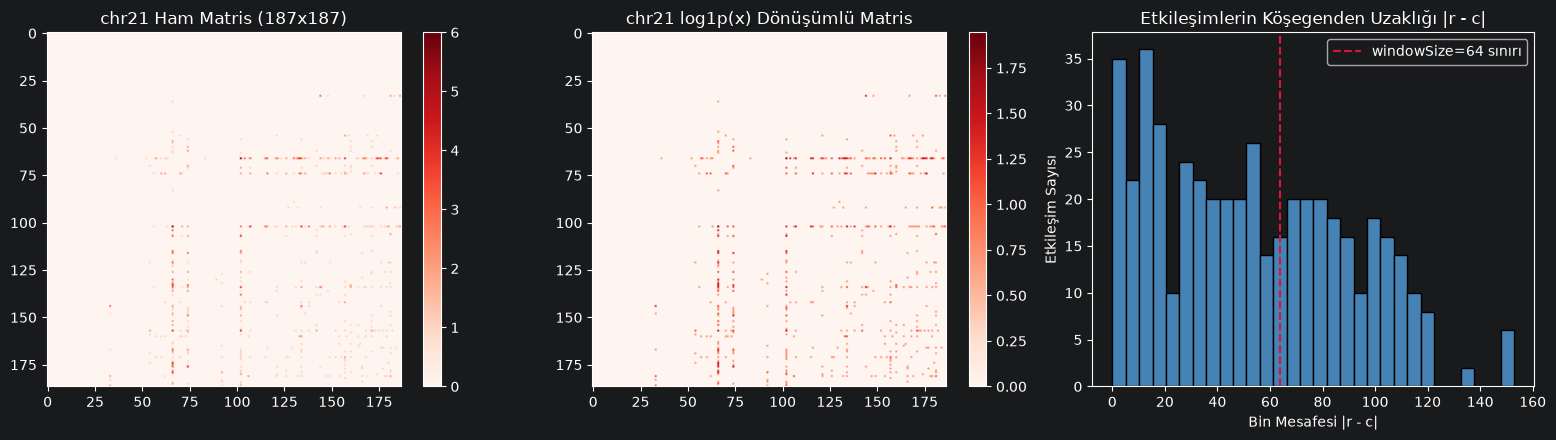

In [3]:
# Örnek bir kromozom (chr21) matrisini utils.getMatrixFromNpz ile yükleyip görselleştirelim
# utils.getMatrixFromNpz fonksiyonu:
#   1. Klasör veya .npz dosyasından ilgili kromozomu bulur
#   2. CSR sparse matrisi yükler
#   3. Klasör adından çözünürlüğü (250kb -> 250000) otomatik çıkarır
sample_mat, inferred_bin_size = utils.getMatrixFromNpz(NPZ_DATA_DIR, "21", pBinSizeInt=BIN_SIZE)
sample_dense = sample_mat.toarray()

# Köşegenden uzaklık (|r - c|) dağılımını hesaplayalım
rows, cols = sample_mat.nonzero()
dists = np.abs(rows - cols)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# 1. Ham etkileşim matrisi
im0 = axes[0].imshow(sample_dense, cmap="Reds")
axes[0].set_title(f"chr21 Ham Matris ({sample_dense.shape[0]}x{sample_dense.shape[1]})")
plt.colorbar(im0, ax=axes[0], fraction=0.046)

# 2. log1p dönüşümlü etkileşim matrisi (kontrastı artırır)
im1 = axes[1].imshow(np.log1p(sample_dense), cmap="Reds")
axes[1].set_title("chr21 log1p(x) Dönüşümlü Matris")
plt.colorbar(im1, ax=axes[1], fraction=0.046)

# 3. Köşegenden uzaklık histogramı
axes[2].hist(dists, bins=30, color="steelblue", edgecolor="black")
axes[2].axvline(64, color="crimson", linestyle="--", label="windowSize=64 sınırı")
axes[2].set_title("Etkileşimlerin Köşegenden Uzaklığı |r - c|")
axes[2].set_xlabel("Bin Mesafesi |r - c|")
axes[2].set_ylabel("Etkileşim Sayısı")
axes[2].legend()

plt.tight_layout()
plt.show()

## 3. 2B Rastgele Matris (`random2d`), Otomatik Padding ve Pencereleme Modları (`diagonal` vs `grid`)

### Neden İki Farklı Pencereleme Modu Var?
- **`diagonal` Modu:** Ana diyagonal boyunca `[i:i+W, i:i+W]` pencereleri kaydırır. Sadece $|r - c| < W$ bandındaki etkileşimleri kapsar. Çok hızlıdır ve GPU üzerinde bant toplama (`predict_band`) destekler.
- **`grid` Modu:** Üst üçgen boyunca $(i \le j)$ tüm `(row_start, col_start)` çiftlerinde `[i:i+W, j:j+W]` pencereleri keser. Böylece diyagonalden çok uzaktaki (trans-benzeri / uzak cis) RNA-DNA etkileşimlerini de modele öğretir ve tahmin eder.

### Otomatik Padding Nasıl Çalışır?
Örneğin `chr21` kromozomu 250kb çözünürlükte **187 bin** uzunluğundadır. Eğer `windowSize=256` seçilirse:
1. `DataContainer.loadData()` otomatik olarak `187 < 256` olduğunu tespit eder,
2. Sağ ve alt kenara `69` bin sıfır dolgusu (`zero-padding`) ekleyerek matrisi `256x256` boyutuna çıkarır ve `[PADDING]` logu basar,
3. Tahmin (`hicPredict`) sonunda yeniden inşa edilen matris otomatik olarak `187x187` orijinal boyutuna kırpılır (`[UNPADDING]`).

In [4]:
# 3.1. Otomatik Padding Gösterimi: chr21 (187 bin) üzerinde windowSize=256 ile DataContainer yükleme
demo_container_pad = dataContainer.DataContainer(
    chromosome="21",
    matrixFilePath=NPZ_DATA_DIR,
    chromatinFolder=None,       # random2d modunda BigWig klasörüne ihtiyaç yoktur
    binSize=BIN_SIZE,
    inputMode="random2d",
    randomSeed=42
)

# windowSize=256 > 187 olduğu için otomatik padding devreye girecek ve loglanacaktır:
demo_container_pad.loadData(
    windowSize=256,
    flankingSize=0,             # random2d modunda flankingSize=0 kullanılır
    scaleFeatures=True,
    scaleTargets=True,
    windowMode="diagonal"
)

print(f"Orijinal bin sayısı   : {demo_container_pad.original_num_bins}")
print(f"Eklenen padding (bin) : {demo_container_pad.padded_bins}")
print(f"Yeni toplam bin sayısı: {demo_container_pad.numBins}")
print(f"Üretilen pencere      : {demo_container_pad.getNumberSamples()} adet (256x256)")
demo_container_pad.unloadData()

INFO:hicgan.lib.utils:[NPZ-LOAD] Loaded /Users/erenyemsen/Documents/Projects/PycharmProjects/Hi-cGAN/data/chrom_npz_homo_sapiens_GRCh38_250kb_tss_count/chr21.npz for chr21: shape=(187, 187), nnz=471, data_range=[1.0000, 6.0000], binSize=250000 bp
INFO:hicgan.lib.dataContainer:Loaded npz matrix /Users/erenyemsen/Documents/Projects/PycharmProjects/Hi-cGAN/data/chrom_npz_homo_sapiens_GRCh38_250kb_tss_count | chr. 21, matshape 187*187 -- min. 0.000 -- max. 1.000 -- nnz. 471
INFO:hicgan.lib.utils:[RANDOM2D] Generated symmetric 2D random matrix for chr21: shape=(187, 187), base_seed=42, derived_seed=16684116170342849221, min=0.0049, max=0.9976, mean=0.4978
INFO:hicgan.lib.dataContainer:[PADDING] Chromosome 21: original_bins=187 < required_bins=256 (windowSize=256, flankingSize=0, inputMode=random2d, windowMode=diagonal). Added +69 zero-padded bins at chromosome end -> new_shape=(256, 256).


Loaded npz matrix /Users/erenyemsen/Documents/Projects/PycharmProjects/Hi-cGAN/data/chrom_npz_homo_sapiens_GRCh38_250kb_tss_count
chr. 21, matshape 187*187 -- min. 0.000 -- max. 1.000 -- nnz. 471
[RANDOM2D] Generated symmetric 2D random matrix for chr21: shape=(187, 187), base_seed=42, derived_seed=16684116170342849221, min=0.0049, max=0.9976, mean=0.4978
[PADDING] Chromosome 21: original_bins=187 < required_bins=256 (windowSize=256, flankingSize=0, inputMode=random2d, windowMode=diagonal). Added +69 zero-padded bins at chromosome end -> new_shape=(256, 256).
Orijinal bin sayısı   : 187
Eklenen padding (bin) : 69
Yeni toplam bin sayısı: 256
Number of samples: 1 | 1 | 0
Üretilen pencere      : 1 adet (256x256)


In [5]:
# 3.2. Diagonal vs Grid Pencereleme Modlarının Karşılaştırılması (windowSize=64)
# NOT: DataContainer.getSampleData(idx) fonksiyonu:
#   {"factorData": (W, W, 1) girdi dizisi, "out_matrixData": (W, W, 1) hedef dizisi}
# şeklinde bir sözlük (dict) döndürür.
for mode in ["diagonal", "grid"]:
    c = dataContainer.DataContainer(
        chromosome="21",
        matrixFilePath=NPZ_DATA_DIR,
        chromatinFolder=None,
        binSize=BIN_SIZE,
        inputMode="random2d",
        randomSeed=42
    )
    c.loadData(
        windowSize=64,
        flankingSize=0,
        scaleFeatures=True,
        scaleTargets=True,
        windowMode=mode,
        gridStride=32  # sadece grid modunda kullanılır (varsayılan: windowSize // 2)
    )
    sample_dict = c.getSampleData(0)
    sample_input = sample_dict["factorData"]
    sample_target = sample_dict["out_matrixData"]
    print(
        f"Mod: {mode:<10} | Toplam Pencere Sayısı: {c.getNumberSamples():<4d} | "
        f"Girdi Boyutu: {sample_input.shape} | Hedef Boyutu: {sample_target.shape}"
    )
    c.unloadData()

INFO:hicgan.lib.utils:[NPZ-LOAD] Loaded /Users/erenyemsen/Documents/Projects/PycharmProjects/Hi-cGAN/data/chrom_npz_homo_sapiens_GRCh38_250kb_tss_count/chr21.npz for chr21: shape=(187, 187), nnz=471, data_range=[1.0000, 6.0000], binSize=250000 bp
INFO:hicgan.lib.dataContainer:Loaded npz matrix /Users/erenyemsen/Documents/Projects/PycharmProjects/Hi-cGAN/data/chrom_npz_homo_sapiens_GRCh38_250kb_tss_count | chr. 21, matshape 187*187 -- min. 0.000 -- max. 1.000 -- nnz. 471
INFO:hicgan.lib.utils:[RANDOM2D] Generated symmetric 2D random matrix for chr21: shape=(187, 187), base_seed=42, derived_seed=16684116170342849221, min=0.0049, max=0.9976, mean=0.4978
INFO:hicgan.lib.dataContainer:[PADDING] Chromosome 21: original_bins=187 >= required_bins=64 (windowSize=64, flankingSize=0) -> no padding needed.
INFO:hicgan.lib.utils:[NPZ-LOAD] Loaded /Users/erenyemsen/Documents/Projects/PycharmProjects/Hi-cGAN/data/chrom_npz_homo_sapiens_GRCh38_250kb_tss_count/chr21.npz for chr21: shape=(187, 187), nnz

Loaded npz matrix /Users/erenyemsen/Documents/Projects/PycharmProjects/Hi-cGAN/data/chrom_npz_homo_sapiens_GRCh38_250kb_tss_count
chr. 21, matshape 187*187 -- min. 0.000 -- max. 1.000 -- nnz. 471
[RANDOM2D] Generated symmetric 2D random matrix for chr21: shape=(187, 187), base_seed=42, derived_seed=16684116170342849221, min=0.0049, max=0.9976, mean=0.4978
Number of samples: 124 | 124 | 0
Mod: diagonal   | Toplam Pencere Sayısı: 124  | Girdi Boyutu: (64, 64, 1) | Hedef Boyutu: (64, 64, 1)
Loaded npz matrix /Users/erenyemsen/Documents/Projects/PycharmProjects/Hi-cGAN/data/chrom_npz_homo_sapiens_GRCh38_250kb_tss_count
chr. 21, matshape 187*187 -- min. 0.000 -- max. 1.000 -- nnz. 471
[RANDOM2D] Generated symmetric 2D random matrix for chr21: shape=(187, 187), base_seed=42, derived_seed=16684116170342849221, min=0.0049, max=0.9976, mean=0.4978
[WINDOW-GRID] Chromosome 21: windowMode=grid, windowSize=64, gridStride=32, 1D_positions=5, upper_triangle_windows=15 (matrix_bins=187, original_bins

## 4. Uçtan Uca Eğitim Pipeline'ı (`hicTraining`)

Her çalıştırmanın birbirinin üzerine yazmaması ve tüm deneylerin ayrı ayrı saklanması için her çalışmaya **tarih-saat ve hiperparametre etiketli (`run_YYYYMMDD_HHMMSS_...`)** benzersiz bir klasör adı verilir:
- `notebook_pipeline_output/<RUN_NAME>/train_run`
- `notebook_pipeline_output/<RUN_NAME>/predict_run`

Aşağıdaki hücrede:
1. Eğitim (`chr21`) ve doğrulama (`chr22`) kromozomları için global hedef değer aralığı (`target_value_range.json`) ölçülür (`logTransformTarget=True` ile `log1p` uzayında),
2. `DataContainer` örnekleri oluşturularak `TFRecord` dosyaları diske yazılır,
3. `HiCGAN` modeli `use_embedding=False` (`cnn_embedding` devre dışı, doğrudan `(W, W, 1)` 2B girdi) ile inşa edilir ve eğitilir.

In [6]:
# Eğitim yapılandırma parametreleri
WINDOW_SIZE = 64          # 64, 128, 256, 512, 768, 1024 seçilebilir
INPUT_MODE = "bigwig"     # 'random2d' (2B rastgele matris) veya 'bigwig' (1B BigWig + cnn_embedding)
WINDOW_MODE = "grid"  # 'diagonal' (ana köşegen) veya 'grid' (tüm üst üçgen 2B ızgara)
GRID_STRIDE = 32          # 'grid' modunda pencere kaydırma adımı
LOG_TRANSFORM = True      # Hedef matrise log1p(x) dönüşümü uygula (tahminde expm1 ile geri çevrilir)
BATCH_SIZE = 8
EPOCHS = 2                # Demo için 2 epoch (gerçek eğitimde 50-200 arası önerilir)
SEED = 42

TRAIN_CHROMS = ["21"]     # Eğitim kromozomları (ör. [str(i) for i in range(1, 21)])
VAL_CHROMS = ["22"]       # Doğrulama kromozomları

# INPUT_MODE == 'bigwig' seçildiğinde kullanılacak kromatin faktör (BigWig) klasörü
# data/bigwig/gm12878/ altındaki klasörlerden istediğinizi seçebilirsiniz:
BIGWIG_FOLDER = os.path.join(
    PROJECT_ROOT, "data", "bigwig", "gm12878", "bigwig_CTCF_SMC3_H3K4me3_RAD21_H3K27ac"
)

# Her çalıştırmayı (run) tarihe ve parametrelere göre ayrı bir klasöre kaydedelim
RUN_TIMESTAMP = datetime.now().strftime("%Y%m%d_%H%M%S")
RUN_NAME = f"run_{RUN_TIMESTAMP}_{INPUT_MODE}_{WINDOW_MODE}_ws{WINDOW_SIZE}_ep{EPOCHS}"

OUTPUT_BASE_DIR = os.path.join(PROJECT_ROOT, "output_models")
RUN_DIR = os.path.join(OUTPUT_BASE_DIR, RUN_NAME)
TRAIN_OUT_DIR = os.path.join(RUN_DIR, "train_run")
PRED_OUT_DIR = os.path.join(RUN_DIR, "predict_run")

# hicTraining CLI argüman listesini hazırlayalım
# Aynı argümanları terminalden `hicTraining ...` komutuyla da çalıştırabilirsiniz.
train_cli_args = [
    "--trainingMatrices", NPZ_DATA_DIR,
    "--trainingChromosomes", *TRAIN_CHROMS,
    "--validationMatrices", NPZ_DATA_DIR,
    "--validationChromosomes", *VAL_CHROMS,
    "--inputMode", INPUT_MODE,
    "--windowMode", WINDOW_MODE,
    "--gridStride", str(GRID_STRIDE),
    "--binSize", str(BIN_SIZE),
    "--windowSize", str(WINDOW_SIZE),
    "--outputFolder", TRAIN_OUT_DIR,
    "--epochs", str(EPOCHS),
    "--batchSize", str(BATCH_SIZE),
    "--plotFrequency", "1",
    "--seed", str(SEED),
    "--keepTFRecords"
]
if INPUT_MODE == "bigwig":
    assert os.path.isdir(BIGWIG_FOLDER), f"BigWig klasörü bulunamadı: {BIGWIG_FOLDER}"
    train_cli_args.extend([
        "--trainingChromatinFolders", BIGWIG_FOLDER,
        "--validationChromatinFolders", BIGWIG_FOLDER,
    ])
if LOG_TRANSFORM:
    train_cli_args.append("--logTransformTarget")

print(f"Aktif Run Adı        : {RUN_NAME}")
print(f"Girdi Modu           : {INPUT_MODE}" + (f" ({BIGWIG_FOLDER})" if INPUT_MODE == "bigwig" else ""))
print(f"Eğitim Çıktı Klasörü : {TRAIN_OUT_DIR}")
print(f"Tahmin Çıktı Klasörü : {PRED_OUT_DIR}")
print("\nÇalıştırılacak hicTraining argümanları:")
print(" ".join(train_cli_args))

Aktif Run Adı        : run_20261023_000733_bigwig_grid_ws64_ep2
Girdi Modu           : bigwig (/Users/erenyemsen/Documents/Projects/PycharmProjects/Hi-cGAN/data/bigwig/gm12878/bigwig_CTCF_SMC3_H3K4me3_RAD21_H3K27ac)
Eğitim Çıktı Klasörü : /Users/erenyemsen/Documents/Projects/PycharmProjects/Hi-cGAN/notebook_pipeline_output/run_20261023_000733_bigwig_grid_ws64_ep2/train_run
Tahmin Çıktı Klasörü : /Users/erenyemsen/Documents/Projects/PycharmProjects/Hi-cGAN/notebook_pipeline_output/run_20261023_000733_bigwig_grid_ws64_ep2/predict_run

Çalıştırılacak hicTraining argümanları:
--trainingMatrices /Users/erenyemsen/Documents/Projects/PycharmProjects/Hi-cGAN/data/chrom_npz_homo_sapiens_GRCh38_250kb_tss_count --trainingChromosomes 21 --validationMatrices /Users/erenyemsen/Documents/Projects/PycharmProjects/Hi-cGAN/data/chrom_npz_homo_sapiens_GRCh38_250kb_tss_count --validationChromosomes 22 --inputMode bigwig --windowMode grid --gridStride 32 --binSize 250000 --windowSize 64 --outputFolder /Use

In [8]:
# Eğitimi başlat! (TFRecord üretimi + Global normalizasyon + Hi-cGAN eğitimi + Model kaydı)
hic_training.main(train_cli_args)

# Eğitim sonunda kaydedilen target_value_range.json dosyasını kontrol edelim
range_json_path = os.path.join(TRAIN_OUT_DIR, "target_value_range.json")
with open(range_json_path, "r") as f:
    print(f"\n[{RUN_NAME}] Kaydedilen target_value_range.json içeriği:")
    print(json.dumps(json.load(f), indent=2))

INFO:hicgan.training:[MAIN] Starting hicTraining: inputMode=bigwig, windowMode=grid, gridStride=32, windowSize=64, binSize=250000, logTransformTarget=True, seed=42
INFO:hicgan.training:Using single GPU training
INFO:hicgan.training:Physically selected GPU: /physical_device:GPU:0
INFO:hicgan.training:[CREATE-DATA] Preparing containers: inputMode=bigwig, windowMode=grid, gridStride=32, windowSize=64, trainChroms=['21'], valChroms=['22']


random seed set to 42
[CREATE-DATA] Preparing containers: inputMode=bigwig, windowMode=grid, gridStride=32, windowSize=64, trainChroms=['21'], valChroms=['22']


INFO:hicgan.lib.utils:[NPZ-INDEX] Loaded n_bins for 24 chromosomes from /Users/erenyemsen/Documents/Projects/PycharmProjects/Hi-cGAN/data/chrom_npz_homo_sapiens_GRCh38_250kb_tss_count/chrom_index.csv
INFO:hicgan.lib.utils:[NPZ-BINSIZE] Inferred binSize=250000 bp from path '/Users/erenyemsen/Documents/Projects/PycharmProjects/Hi-cGAN/data/chrom_npz_homo_sapiens_GRCh38_250kb_tss_count'
INFO:hicgan.lib.utils:[NPZ-LOAD] Loaded /Users/erenyemsen/Documents/Projects/PycharmProjects/Hi-cGAN/data/chrom_npz_homo_sapiens_GRCh38_250kb_tss_count/chr21.npz for chr21: shape=(187, 187), nnz=471, data_range=[1.0000, 6.0000], binSize=250000 bp
INFO:hicgan.lib.utils:[TARGET-RANGE] Measured global target value range: [0.0000, 1.9459] (logTransform=True)
INFO:hicgan.lib.utils:wrote target value range [0, 1.94591] (log_transform=True) to /Users/erenyemsen/Documents/Projects/PycharmProjects/Hi-cGAN/notebook_pipeline_output/run_20261023_000733_bigwig_grid_ws64_ep2/train_run/target_value_range.json
INFO:hicgan

[TARGET-SCALE] Global target value range measured from training targets (log1p=True): [0.0000, 1.9459] -> mapped to [0, 1] (saved to /Users/erenyemsen/Documents/Projects/PycharmProjects/Hi-cGAN/notebook_pipeline_output/run_20261023_000733_bigwig_grid_ws64_ep2/train_run/target_value_range.json)


INFO:hicgan.training:[CREATE-DATA] Loading TRAIN container for chr21...
INFO:hicgan.lib.utils:[NPZ-LOAD] Loaded /Users/erenyemsen/Documents/Projects/PycharmProjects/Hi-cGAN/data/chrom_npz_homo_sapiens_GRCh38_250kb_tss_count/chr21.npz for chr21: shape=(187, 187), nnz=471, data_range=[1.0000, 6.0000], binSize=250000 bp
INFO:hicgan.lib.dataContainer:Loaded npz matrix /Users/erenyemsen/Documents/Projects/PycharmProjects/Hi-cGAN/data/chrom_npz_homo_sapiens_GRCh38_250kb_tss_count | chr. 21, matshape 187*187 -- min. 0.000 -- max. 6.000 -- nnz. 471
INFO:hicgan.lib.dataContainer:[BIGWIG-ALIGN] Chromosome 21: BigWig bins (193) > target .npz bins (187). Cropped BigWig features to 187 bins.


...

[MODEL-INIT] HiCGAN configuration: input_size=64, number_factors=10, use_embedding=True (1D BigWig -> cnn_embedding), enforce_symmetry=False, loss_type_pixel=L1, mixed_precision=False


INFO:hicgan.training:Starting training at 2026-10-23 00:08:09.883806


skipping the architecture diagram /Users/erenyemsen/Documents/Projects/PycharmProjects/Hi-cGAN/notebook_pipeline_output/run_20261023_000733_bigwig_grid_ws64_ep2/train_run/generatorModel.png: You must install graphviz (see instructions at https://graphviz.gitlab.io/download/) for `plot_model` to work.. Install pydot and graphviz if you want it; training is unaffected.


Epoch 00001:   0%|          | 0/1 [00:00<?, ?it/s]
INFO:absl:Sharding callback duration: 22
Epoch 00002:   0%|          | 0/1 [00:00<?, ?it/s]
INFO:absl:Sharding callback duration: 21
INFO:hicgan.training:Training finished at 2026-10-23 00:08:13.050706



[run_20261023_000733_bigwig_grid_ws64_ep2] Kaydedilen target_value_range.json içeriği:
{
  "min": 0.0,
  "max": 1.945910096168518,
  "log_transform": true
}


## 5. Uçtan Uca Tahmin (Prediction) ve Matris Yeniden İnşası (`hicPredict`)

Eğitilen `Generator` modelini (`generator_00001.keras`) kullanarak:
1. Test kromozomları (`chr21` ve `chr22`) için aynı deterministik tohum (`SEED=42`) ile 2B rastgele girdi matrisleri üretilir,
2. Model her pencere için `[0, 1]` aralığında tahmin üretir,
3. Üst üste binen pencereler birleştirilir (`diagonal` modda GPU üzerinde `predict_band` + `rebuildChromosomeFromBand`, `grid` modda `rebuildChromosomeFromGrid`),
4. Eğer kromozom dolgulanmışsa (`padded_bins > 0`) otomatik olarak orijinal bin sayısına (`original_num_bins`) kırpılır (`[UNPADDING]`),
5. `target_value_range.json` kullanılarak `[0, 1]` aralığından gerçek etkileşim sayılarına (`expm1`) geri dönüştürülür,
6. Sonuçlar aktif run klasörü (`PRED_OUT_DIR`) altına **iki formatta** diske yazılır:
   - `PRED_OUT_DIR/npz_matrices/chr{X}.npz` (tam simetrik `csr_matrix`) + `chrom_index.csv` (girdi veri setiyle birebir aynı format!)
   - `PRED_OUT_DIR/predMatrix.cool` (Cooler formatı)

In [15]:
# Tahmin (predict) edilmesini istediğiniz kromozomları buradan belirleyebilirsiniz
# Örn: ["21", "22"] veya ["1", "2", "21", "22"] veya [str(i) for i in range(1, 23)]
PRED_CHROMS = ["21", "22"]

# Son epoch'ta kaydedilen eğitilmiş Generator modelinin yolunu bulalım
trained_generator_path = os.path.join(TRAIN_OUT_DIR, f"generator_{EPOCHS - 1:05d}.keras")
assert os.path.exists(trained_generator_path), f"Model bulunamadı: {trained_generator_path}"

# hicPredict CLI argümanlarını hazırlayalım
predict_cli_args = [
    "--trainedModel", trained_generator_path,
    "--chromSizesPath", CHROM_INDEX_CSV,     # Kromozom bin sayılarını chrom_index.csv'den alır
    "--predictionChromosomes", *PRED_CHROMS,
    "--inputMode", INPUT_MODE,
    "--windowMode", WINDOW_MODE,
    "--gridStride", str(GRID_STRIDE),
    "--windowSize", str(WINDOW_SIZE),
    "--binSize", str(BIN_SIZE),
    "--batchSize", str(BATCH_SIZE),
    "--targetValueRange", range_json_path,   # [0, 1] ve log1p dönüşümünü geri alır
    "--outputFolder", PRED_OUT_DIR,
    "--matrixOutputName", "predMatrix.cool",
    "--seed", str(SEED),
    "--rebuildProcesses", "1"
]
if INPUT_MODE == "bigwig":
    assert os.path.isdir(BIGWIG_FOLDER), f"BigWig klasörü bulunamadı: {BIGWIG_FOLDER}"
    predict_cli_args.extend([
        "--predictionChromosomesFolders", BIGWIG_FOLDER
    ])

print(f"[{RUN_NAME}] Tahmin edilecek kromozomlar: {PRED_CHROMS}")
print(f"[{RUN_NAME}] Çalıştırılacak hicPredict argümanları:")
print(" ".join(predict_cli_args))

# Tahmin ve matris inşa sürecini çalıştır!
hic_predict.main(predict_cli_args)

INFO:hicgan.predict:Physically selected GPU: /physical_device:GPU:0
INFO:hicgan.predict:Other GPUs are now invisible to TensorFlow.
INFO:hicgan.predict:[PREDICT-SCALE] Undoing unit-range mapping with [0, 1.94591] (expm1=True)


[run_20261023_000733_bigwig_grid_ws64_ep2] Tahmin edilecek kromozomlar: ['21', '22']
[run_20261023_000733_bigwig_grid_ws64_ep2] Çalıştırılacak hicPredict argümanları:
--trainedModel /Users/erenyemsen/Documents/Projects/PycharmProjects/Hi-cGAN/notebook_pipeline_output/run_20261023_000733_bigwig_grid_ws64_ep2/train_run/generator_00001.keras --chromSizesPath /Users/erenyemsen/Documents/Projects/PycharmProjects/Hi-cGAN/data/chrom_npz_homo_sapiens_GRCh38_250kb_tss_count/chrom_index.csv --predictionChromosomes 21 22 --inputMode bigwig --windowMode grid --gridStride 32 --windowSize 64 --binSize 250000 --batchSize 8 --targetValueRange /Users/erenyemsen/Documents/Projects/PycharmProjects/Hi-cGAN/notebook_pipeline_output/run_20261023_000733_bigwig_grid_ws64_ep2/train_run/target_value_range.json --outputFolder /Users/erenyemsen/Documents/Projects/PycharmProjects/Hi-cGAN/notebook_pipeline_output/run_20261023_000733_bigwig_grid_ws64_ep2/predict_run --matrixOutputName predMatrix.cool --seed 42 --reb

INFO:hicgan.predict:[PREDICT-SETUP] inputMode=bigwig, windowMode=grid, gridStride=32, windowSize=64, flankingSize=64, binSize=250000, mode=all, seed=42
INFO:hicgan.lib.utils:[NPZ-INDEX] Loaded n_bins for 24 chromosomes from /Users/erenyemsen/Documents/Projects/PycharmProjects/Hi-cGAN/data/chrom_npz_homo_sapiens_GRCh38_250kb_tss_count/chrom_index.csv
INFO:hicgan.predict:[PREDICT-DATA] Resolved target n_bins=187 for chr21 from /Users/erenyemsen/Documents/Projects/PycharmProjects/Hi-cGAN/data/chrom_npz_homo_sapiens_GRCh38_250kb_tss_count/chrom_index.csv (bigwig mode)
INFO:hicgan.lib.utils:[NPZ-INDEX] Loaded n_bins for 24 chromosomes from /Users/erenyemsen/Documents/Projects/PycharmProjects/Hi-cGAN/data/chrom_npz_homo_sapiens_GRCh38_250kb_tss_count/chrom_index.csv
INFO:hicgan.predict:[PREDICT-DATA] Resolved target n_bins=204 for chr22 from /Users/erenyemsen/Documents/Projects/PycharmProjects/Hi-cGAN/data/chrom_npz_homo_sapiens_GRCh38_250kb_tss_count/chrom_index.csv (bigwig mode)
INFO:hicga

Loaded 5 chromatin features (x2 for grid row/col pairs = 10 input channels) from folder /Users/erenyemsen/Documents/Projects/PycharmProjects/Hi-cGAN/data/bigwig/gm12878/bigwig_CTCF_SMC3_H3K4me3_RAD21_H3K27ac
/Users/erenyemsen/Documents/Projects/PycharmProjects/Hi-cGAN/data/bigwig/gm12878/bigwig_CTCF_SMC3_H3K4me3_RAD21_H3K27ac/CTCF.bigwig - min. 0.000 - max. 1.000 - nnz. 144 (74.61%)
/Users/erenyemsen/Documents/Projects/PycharmProjects/Hi-cGAN/data/bigwig/gm12878/bigwig_CTCF_SMC3_H3K4me3_RAD21_H3K27ac/H3K27ac.bigwig - min. 0.000 - max. 1.000 - nnz. 145 (75.13%)
/Users/erenyemsen/Documents/Projects/PycharmProjects/Hi-cGAN/data/bigwig/gm12878/bigwig_CTCF_SMC3_H3K4me3_RAD21_H3K27ac/H3K4me3.bigwig - min. 0.000 - max. 1.000 - nnz. 145 (75.13%)
/Users/erenyemsen/Documents/Projects/PycharmProjects/Hi-cGAN/data/bigwig/gm12878/bigwig_CTCF_SMC3_H3K4me3_RAD21_H3K27ac/RAD21.bigwig - min. 0.000 - max. 1.000 - nnz. 144 (74.61%)
/Users/erenyemsen/Documents/Projects/PycharmProjects/Hi-cGAN/data/bigwig/

INFO:hicgan.lib.dataContainer:[PADDING] Chromosome 21: original_bins=187 < required_bins=192 (windowSize=64, flankingSize=64, inputMode=bigwig, windowMode=grid). Added +5 zero-padded bins at chromosome end -> new_shape=(192, 192).


...

INFO:hicgan.predict:[PREDICT-GRID] Predicted 1 2D grid windows for chr21 -> /Users/erenyemsen/Documents/Projects/PycharmProjects/Hi-cGAN/notebook_pipeline_output/run_20261023_000733_bigwig_grid_ws64_ep2/predict_run/prediction_chunks/pred_grid_chr21.npy (paddedBins=192, origBins=187)
DEBUG:h5py._conv:Creating converter from 7 to 5
DEBUG:h5py._conv:Creating converter from 5 to 7
DEBUG:h5py._conv:Creating converter from 7 to 5
DEBUG:h5py._conv:Creating converter from 5 to 7
INFO:hicgan.predict:[PREDICT-GRID] Predicted 3 2D grid windows for chr22 -> /Users/erenyemsen/Documents/Projects/PycharmProjects/Hi-cGAN/notebook_pipeline_output/run_20261023_000733_bigwig_grid_ws64_ep2/predict_run/prediction_chunks/pred_grid_chr22.npy (paddedBins=204, origBins=204)
INFO:hicgan.predict:Cleaning up temporary files...
INFO:hicgan.predict:Wrote predictions to /Users/erenyemsen/Documents/Projects/PycharmProjects/Hi-cGAN/notebook_pipeline_output/run_20261023_000733_bigwig_grid_ws64_ep2/predict_run/predictio

[UNPADDING] Chromosome 21: cropped padded matrix from shape=(192, 192) back to original_shape=(187, 187) (removed 5 padded bins)
  chr21  rebuilt, 4,096 stored pixels
  chr22  rebuilt, 5,776 stored pixels


INFO:hicgan.lib.utils:[GRID-REBUILD] Rebuilding chr21 from 1 2D grid windows (windowSize=64, matrixSize=192, originalSize=187)
INFO:hicgan.lib.utils:[UNPADDING] Chromosome 21: cropped padded matrix from shape=(192, 192) back to original_shape=(187, 187) (removed 5 padded bins)
INFO:hicgan.lib.utils:[GRID-REBUILD] Rebuilding chr22 from 3 2D grid windows (windowSize=64, matrixSize=204, originalSize=204)
INFO:hicgan.predict:[NPZ-EXPORT] Writing per-chromosome .npz files and chrom_index.csv to /Users/erenyemsen/Documents/Projects/PycharmProjects/Hi-cGAN/notebook_pipeline_output/run_20261023_000733_bigwig_grid_ws64_ep2/predict_run/npz_matrices...
INFO:hicgan.lib.utils:[NPZ-EXPORT] Saved /Users/erenyemsen/Documents/Projects/PycharmProjects/Hi-cGAN/notebook_pipeline_output/run_20261023_000733_bigwig_grid_ws64_ep2/predict_run/npz_matrices/chr21.npz: shape=(187, 187), nnz=4096 (symmetric CSR)
INFO:hicgan.lib.utils:[NPZ-EXPORT] Saved /Users/erenyemsen/Documents/Projects/PycharmProjects/Hi-cGAN/n

[NPZ-EXPORT] Wrote 2 chromosome .npz files and /Users/erenyemsen/Documents/Projects/PycharmProjects/Hi-cGAN/notebook_pipeline_output/run_20261023_000733_bigwig_grid_ws64_ep2/predict_run/npz_matrices/chrom_index.csv


INFO:hicgan.predict:Writing predicted matrix to disk on /Users/erenyemsen/Documents/Projects/PycharmProjects/Hi-cGAN/notebook_pipeline_output/run_20261023_000733_bigwig_grid_ws64_ep2/predict_run/predMatrix.cool...
INFO:hicgan.lib.utils:Processing chromosome 21 (1/2)
INFO:hicgan.lib.utils:Processing chromosome 22 (2/2)
INFO:hicgan.lib.utils:Writing cooler file to /Users/erenyemsen/Documents/Projects/PycharmProjects/Hi-cGAN/notebook_pipeline_output/run_20261023_000733_bigwig_grid_ws64_ep2/predict_run/predMatrix.cool


## 6. Üretilen `.npz` Matrislerinin Doğrulanması ve Görselleştirilmesi

Aşağıdaki hücrede `VISUALIZE_AND_PREDICT_CHROMS` listesine istediğiniz kromozomları (ör. `["21", "22"]` veya `["19", "20", "21", "22"]`) yazabilirsiniz:
- Eğer listedeki bir kromozom henüz tahmin edilmemişse otomatik olarak `hicPredict` çalıştırılıp `.npz` matrisi üretilir,
- Ardından listedeki **tüm kromozomlar** için gerçek (Ground Truth) ve tahmin edilen (Predicted) `.npz` matrisleri yüklenerek boyut, simetri kontrolleri ve yan yana ısı haritaları (`log1p`) çizdirilir.

INFO:hicgan.lib.utils:[NPZ-LOAD] Loaded /Users/erenyemsen/Documents/Projects/PycharmProjects/Hi-cGAN/data/chrom_npz_homo_sapiens_GRCh38_250kb_tss_count/chr21.npz for chr21: shape=(187, 187), nnz=471, data_range=[1.0000, 6.0000], binSize=250000 bp
INFO:hicgan.lib.utils:[NPZ-LOAD] Loaded /Users/erenyemsen/Documents/Projects/PycharmProjects/Hi-cGAN/data/chrom_npz_homo_sapiens_GRCh38_250kb_tss_count/chr22.npz for chr22: shape=(204, 204), nnz=1750, data_range=[1.0000, 13.0000], binSize=250000 bp


[run_20261023_000733_bigwig_grid_ws64_ep2] Üretilen npz_matrices/chrom_index.csv içeriği:
chrom,n_bins,offset,nnz
21,187,0,4096
22,204,187,5776

chr21  | Gerçek boyut: (187, 187) (nnz=471   ) | Tahmin boyut: (187, 187) (nnz=4096  ) | Tam Simetrik: True
chr22  | Gerçek boyut: (204, 204) (nnz=1750  ) | Tahmin boyut: (204, 204) (nnz=5776  ) | Tam Simetrik: True


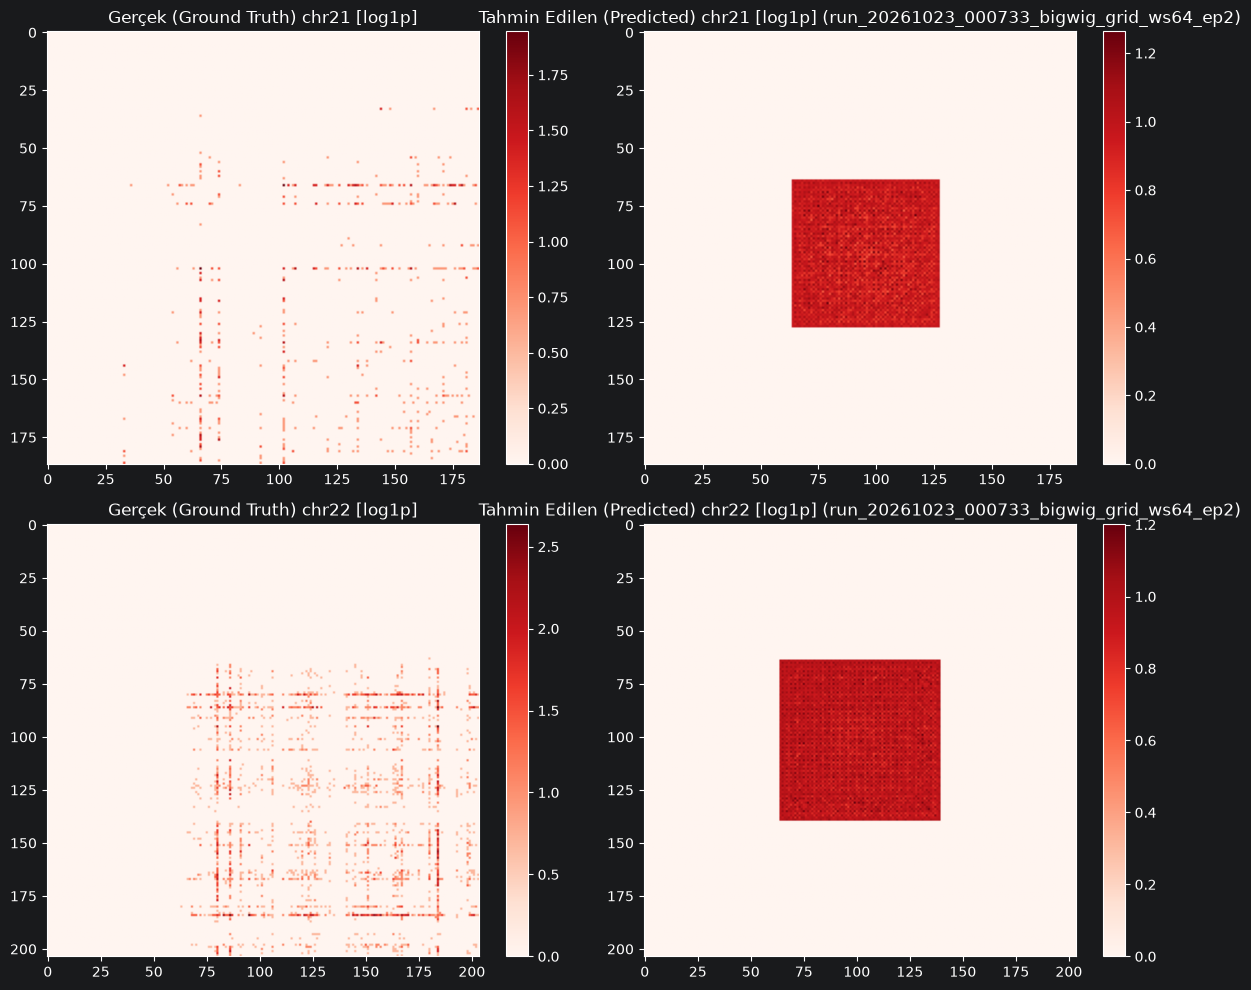

In [16]:
%matplotlib inline
import matplotlib.pyplot as plt

# Doğrulamak ve görselleştirmek (gerekirse tahmin etmek) istediğiniz kromozomları buraya yazın:
# Varsayılan olarak 5. adımdaki PRED_CHROMS listesini kullanır, dilerseniz doğrudan değiştirebilirsiniz (ör. ["20", "21", "22"]).
VISUALIZE_AND_PREDICT_CHROMS = [str(c).lstrip("chr") for c in PRED_CHROMS]

pred_npz_dir = os.path.join(PRED_OUT_DIR, "npz_matrices")

# Eğer listede henüz tahmin edilmemiş (.npz dosyası oluşmamış) kromozom varsa otomatik predict çalıştır
missing_chroms = [
    c for c in VISUALIZE_AND_PREDICT_CHROMS
    if not os.path.exists(os.path.join(pred_npz_dir, f"chr{c}.npz"))
]
if missing_chroms:
    print(f"Henüz tahmin edilmemiş kromozomlar tespit edildi: {missing_chroms}. Tahmin başlatılıyor...")
    extra_pred_args = [
        "--trainedModel", trained_generator_path,
        "--chromSizesPath", CHROM_INDEX_CSV,
        "--predictionChromosomes", *VISUALIZE_AND_PREDICT_CHROMS,
        "--inputMode", INPUT_MODE,
        "--windowMode", WINDOW_MODE,
        "--gridStride", str(GRID_STRIDE),
        "--windowSize", str(WINDOW_SIZE),
        "--binSize", str(BIN_SIZE),
        "--batchSize", str(BATCH_SIZE),
        "--targetValueRange", range_json_path,
        "--outputFolder", PRED_OUT_DIR,
        "--matrixOutputName", "predMatrix.cool",
        "--seed", str(SEED),
        "--rebuildProcesses", "1"
    ]
    if INPUT_MODE == "bigwig":
        extra_pred_args.extend(["--predictionChromosomesFolders", BIGWIG_FOLDER])
    hic_predict.main(extra_pred_args)

pred_index_csv = os.path.join(pred_npz_dir, "chrom_index.csv")
print(f"[{RUN_NAME}] Üretilen npz_matrices/chrom_index.csv içeriği:")
with open(pred_index_csv, "r") as f:
    print(f.read())

# Seçilen her kromozom için doğrulama ve yan yana görselleştirme
n_chroms = len(VISUALIZE_AND_PREDICT_CHROMS)
fig, axes = plt.subplots(n_chroms, 2, figsize=(12, 5 * n_chroms), squeeze=False)

for row_idx, chrom in enumerate(VISUALIZE_AND_PREDICT_CHROMS):
    gt_mat, _ = utils.getMatrixFromNpz(NPZ_DATA_DIR, chrom, pBinSizeInt=BIN_SIZE)
    pred_path = os.path.join(pred_npz_dir, f"chr{chrom}.npz")
    pred_mat = sparse.load_npz(pred_path)

    gt_dense = gt_mat.toarray()
    pred_dense = pred_mat.toarray()
    is_sym = (pred_mat - pred_mat.T).nnz == 0 or np.allclose(pred_dense, pred_dense.T)

    print(
        f"chr{chrom:<3s} | Gerçek boyut: {str(gt_mat.shape):<10s} (nnz={gt_mat.nnz:<6d}) | "
        f"Tahmin boyut: {str(pred_mat.shape):<10s} (nnz={pred_mat.nnz:<6d}) | Tam Simetrik: {is_sym}"
    )

    ax_gt = axes[row_idx, 0]
    im_gt = ax_gt.imshow(np.log1p(gt_dense), cmap="Reds")
    ax_gt.set_title(f"Gerçek (Ground Truth) chr{chrom} [log1p]")
    plt.colorbar(im_gt, ax=ax_gt, fraction=0.046)

    ax_pred = axes[row_idx, 1]
    im_pred = ax_pred.imshow(np.log1p(pred_dense), cmap="Reds")
    ax_pred.set_title(f"Tahmin Edilen (Predicted) chr{chrom} [log1p] ({RUN_NAME})")
    plt.colorbar(im_pred, ax=ax_pred, fraction=0.046)

plt.tight_layout()
plt.show()

## 7. Terminalden 1B BigWig Feature'ları ile Çalıştırma (`inputMode="bigwig"`)

Notebook dışında terminalden (CLI) `data/bigwig/gm12878/` altındaki **BigWig (`.bw` / `.bigwig`)** dosyalarını girdi olarak vermek istediğinizde `--inputMode bigwig` ve `-tcp` / `-vcp` parametrelerini şu şekilde kullanabilirsiniz:

```bash
# 1B BigWig Girdisi + cnn_embedding ile Eğitim:
hicTraining \
  -tm data/chrom_npz_homo_sapiens_GRCh38_250kb_tss_count \
  -tchroms 1 2 3 4 5 6 7 8 9 10 11 12 13 14 15 16 17 18 19 20 \
  -tcp data/bigwig/gm12878/bigwig_CTCF_SMC3_H3K4me3_RAD21_H3K27ac \
  -vm data/chrom_npz_homo_sapiens_GRCh38_250kb_tss_count \
  -vchroms 21 22 \
  -vcp data/bigwig/gm12878/bigwig_CTCF_SMC3_H3K4me3_RAD21_H3K27ac \
  --inputMode bigwig \
  --windowMode diagonal \
  --binSize 250000 \
  --windowSize 64 \
  --logTransformTarget \
  --epochs 100 \
  -o outputs/bigwig_run_$(date +%Y%m%d_%H%M%S)/train

# 1B BigWig Girdisi ile Tahmin:
hicPredict \
  -trm outputs/bigwig_run_<TIMESTAMP>/train/generator_00099.keras \
  -tcp data/bigwig/gm12878/bigwig_CTCF_SMC3_H3K4me3_RAD21_H3K27ac \
  -csp data/chrom_npz_homo_sapiens_GRCh38_250kb_tss_count/chrom_index.csv \
  -pc 21 22 \
  --inputMode bigwig \
  --windowMode diagonal \
  --windowSize 64 \
  --binSize 250000 \
  -tvr outputs/bigwig_run_<TIMESTAMP>/train/target_value_range.json \
  -o outputs/bigwig_run_<TIMESTAMP>/predict
```